In [ ]:
import numpy as np
import pandas as pd

In [ ]:
fake = pd.read_csv('/content/drive/MyDrive/dataset/Fake.csv')
real = pd.read_csv('/content/drive/MyDrive/dataset/True.csv')

In [ ]:
real['label'] = 1
fake['label'] = 0

# Combine real and fake into one dataset
df = pd.concat([real, fake], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


df.head()

,title,text,subject,date,label
0,BREAKING: GOP Chairman Grassley Has Had Enoug...,"Donald Trump s White House is in chaos, and th...",News,"July 21, 2017",0
1,Failed GOP Candidates Remembered In Hilarious...,Now that Donald Trump is the presumptive GOP n...,News,"May 7, 2016",0
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY...,Mike Pence is a huge homophobe. He supports ex...,News,"December 3, 2016",0
3,California AG pledges to defend birth control ...,SAN FRANCISCO (Reuters) - California Attorney ...,politicsNews,"October 6, 2017",1
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,politics,"Apr 25, 2017",0


In [ ]:
df.shape

(44898, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
 5   texts    44898 non-null  object
dtypes: int64(1), object(5)
memory usage: 2.1+ MB


In [ ]:
df.isnull().sum()

,0
title,0
text,0
subject,0
date,0
label,0
texts,0


In [ ]:
df.columns

Index(['title', 'text', 'subject', 'date', 'label', 'texts'], dtype='object')

In [ ]:
print(df.duplicated().sum())

209


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.shape

(44689, 6)

In [ ]:
df['label'].value_counts()

,count
label,
0,23478
1,21211


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

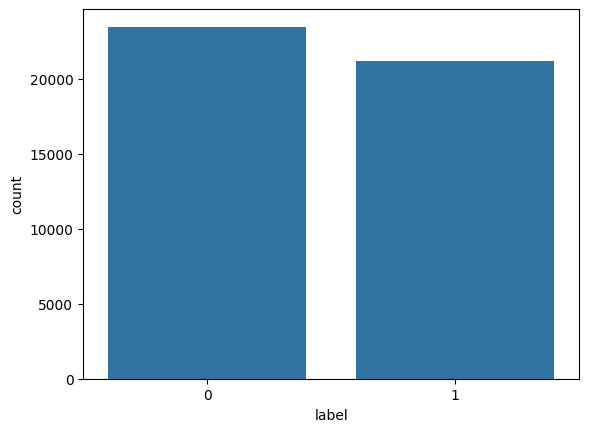

In [ ]:
sns.countplot(x='label', data=df)
plt.show()

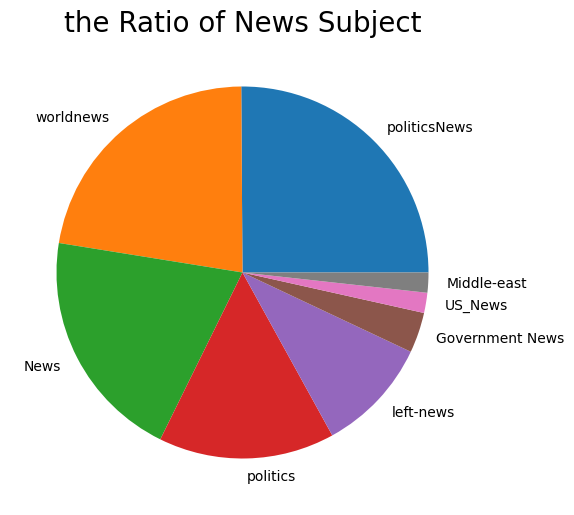

In [ ]:
plt.figure(figsize=(6,8))
plt.pie(x = df['subject'].value_counts() ,labels=df['subject'].value_counts().index)
plt.title('the Ratio of News Subject',fontsize=20)
plt.show()

In [ ]:
pip install nltk

In [ ]:
import nltk
nltk.download('punkt_tab')
nltk.download('pumkit')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Error loading pumkit: Package 'pumkit' not found in index
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import string
import re

In [ ]:
stop_words = set(stopwords.words('english'))
ps = PorterStemmer()
lemma = WordNetLemmatizer()

In [ ]:
def clean (text):
 text = re.sub(r'[^\w\s+]', ' ', text)
 text = re.sub(r'[^a-zA-Z]', ' ', text)
 text = re.sub(r'\s+', ' ', text)
 text = text.lower()
 tokens = word_tokenize(text)
 tokens = [word for word in tokens if word not in stop_words]
 tokens = [lemmatizer.lemmatize(word) for word in tokens]
 return " ".join(tokens)




In [ ]:
df['texts'] = df['texts'].astype(str).apply(clean)

df.head()

,title,text,subject,date,label,texts
0,BREAKING: GOP Chairman Grassley Has Had Enoug...,"Donald Trump s White House is in chaos, and th...",News,"July 21, 2017",0,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious...,Now that Donald Trump is the presumptive GOP n...,News,"May 7, 2016",0,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY...,Mike Pence is a huge homophobe. He supports ex...,News,"December 3, 2016",0,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,SAN FRANCISCO (Reuters) - California Attorney ...,politicsNews,"October 6, 2017",1,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,politics,"Apr 25, 2017",0,az rancher living u mexico border destroy nanc...


In [ ]:
# The initialization of x and y is now handled in cell JDvTgf47AV2S
x = df['texts'] # Initialize x with the cleaned text
y = df['label']

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,3))

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)
x_train=tfidf.fit_transform(x_train)
x_test=tfidf.transform(x_test)

In [ ]:
from xgboost import XGBClassifier
best_model = XGBClassifier(eval_metric="logloss",use_label_encoder=False,random_state=42)
best_model.fit(x_train, y_train)
y_pred = best_model.predict(x_test)


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:47:41] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
print(accuracy_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)

0.9987469793251589
[[5926    7]
 [   7 5233]]


In [ ]:
""" Precision

Out of predicted fake news,
how many were actually fake?

Recall

Out of all fake news,
how many did model catch?"""

' Precision\n\nOut of predicted fake news,\nhow many were actually fake?\n\nRecall\n\nOut of all fake news,\nhow many did model catch?'

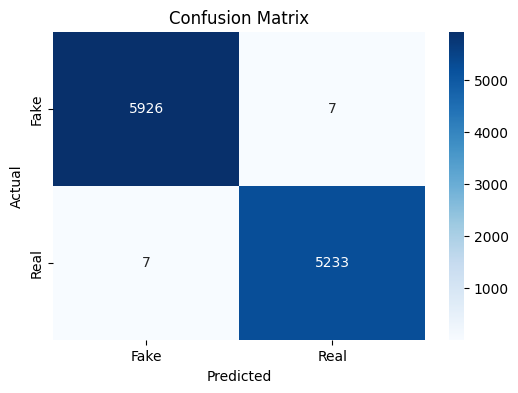

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
news = "WASHINGTON (Reuters) - The World Health Organization released updated guidelines on air pollution."

cleaned = clean(news)
print(cleaned)
vec = tfidf.transform([cleaned])

prediction = best_model.predict(vec)
print(best_model.predict_proba(vec))

washington reuters world health organization released updated guideline air pollution
[[5.6147575e-05 9.9994385e-01]]


In [ ]:
if prediction[0] == 1:
    print("Real News")
else:
    print("Fake News")

Real News


In [ ]:

publisher_pattern = 'WASHINGTON \(Reuters\)|SAN FRANCISCO \(Reuters\)'
# This looks for any text that contains "SAN FRANCISCO (Reuters)"
reuters_articles = df[df['text'].str.contains(publisher_pattern, na=False)]
#str: Tells Pandas to treat the whole column as text (strings) so you can do text searches.
#na=False: If there are any completely blank or missing text rows in your data, this ensures the code doesn't crash and just skips them.

# This will show you how many of those articles are labeled as Real (1) vs Fake (0)
print(reuters_articles['label'].value_counts())

<>:1: SyntaxWarning: invalid escape sequence '\('
<>:1: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_375/48303079.py:1: SyntaxWarning: invalid escape sequence '\('
  publisher_pattern = 'WASHINGTON \(Reuters\)|SAN FRANCISCO \(Reuters\)'


label
1    6751
0       3
Name: count, dtype: int64
